# Triagem de anomalias na decolagem — versão modificada

| | |
|---|---|
| **Disciplina** | TE-292 — Ciência de Dados em Operação e Manutenção de Aeronaves |
| **Instituição** | Instituto Tecnológico de Aeronáutica (ITA) — AeroLogLab |
| **Professor** | Antonio Celio Pereira de Mesquita |
| **Aluno** | João Paulo Gomes de Oliveira |
| **Aula** | XAI: explicabilidade e confiança |
| | |

**Em uma frase**: temos 500 decolagens gravadas automaticamente, nenhuma delas marcada por
um humano como "normal" ou "problemática". Vamos pedir ao computador para apontar, sozinho,
quais decolagens parecem diferentes das demais, **explicar por que** ele fez cada escolha e
**medir o quanto podemos confiar** nessa lista — para que um especialista humano decida o que
fazer com ela.

**Escopo**

- Somente a fase de **decolagem**: janelas de 61 s (1 Hz) que começam quando a velocidade
  indicada atinge ~40 kt na corrida de decolagem.
- Frota única de monomotor turboélice, **10 aeronaves anonimizadas** (`ANV_A` … `ANV_J`),
  **50 decolagens por aeronave**, sem rótulo de referência.
- Método principal preservado do notebook original: **PCA (90% da variância) + DBSCAN** em
  configuração literal (estilo *ClusterAD-Flight* — Li et al., `[CITATION NEEDED]`) sobre
  janelas vetorizadas, com a **distância-K** como pontuação contínua de atipicidade.
- Os "candidatos" são **material para revisão especializada**; o diagnóstico é sempre humano.

## O que mudou em relação ao notebook original

O notebook original (`decolagem_deteccao_anomalias.ipynb`, **não alterado**) lia arquivos
Parquet de voo completo em `time_history_1hz_analysis/` (EMB 314, 519 arquivos, 8 aeronaves).
Essa pasta **não existe** neste projeto; a única fonte de dados disponível na pasta da aula é
`dataset_ouro_decolagens_500_anonimizado.csv`, que passa a ser a **fonte oficial** desta versão.
Ela tem outro esquema de colunas e já vem janelada, e isso obrigou a adaptar o pipeline:

| Etapa | Original | Esta versão | Motivo |
|---|---|---|---|
| Fonte | Parquet por voo (ausente) | CSV único, 30 500 linhas | único dataset disponível |
| Âncora | 1º cruzamento de 250 ft AGL, janela de 70 s **antes** | janela nativa do dataset: 61 s **a partir de** IAS ≈ 40 kt | o CSV não traz o trecho anterior à corrida |
| Validade | flags `*_is_valid` | ausência de valor (`NaN`) | o CSV não tem flags |
| Rumo | `MAG_HDG` relativo | — (coluna ausente) | — |
| Altura | excluída (era a variável da âncora) | **ganho de altura relativo** (`AltB − AltB[t=0]`) | a âncora agora é IAS; a altura relativa independe da elevação da pista |
| Colunas derivadas | — | excluídas | são funções exatas de colunas já incluídas (validado na §4) |
| Confundidor testado | carga externa | cabeceira de pista e temperatura externa (OAT) | o CSV não tem dados de carga |
| Correção de Holm | `statsmodels` | implementação local (5 linhas) | evita dependência não instalada |

**Melhorias metodológicas** (detalhadas nas seções correspondentes):

1. **Checagem de consistência** entre o rótulo do DBSCAN e a distância-K (§8).
2. **Avaliação sem rótulo**: plausibilidade física contra eventos de referência definidos por
   regras *a priori* e concordância com dois detectores independentes (§9).
3. **XAI fiel ao modelo**: decomposição **exata e aditiva** da distância-K por parâmetro e por
   segundo — o item que o original deixava como "trabalho futuro" (§11). O diagnóstico por
   z-score do original foi mantido como verificação cruzada.
4. **Confiança**: estabilidade por reamostragem, sensibilidade a hiperparâmetros e *hold-out*
   temporal — a "bateria de robustez" que o original deixava fora do recorte (§12).

## Termos usados neste notebook

- **Janela de decolagem**: os 61 segundos (t = 0 … 60 s) a partir do instante em que a
  velocidade indicada atinge ~40 kt na corrida.
- **Vetor / vetorização**: transformar os 61 s de um voo — para cada parâmetro medido — numa
  única lista longa de números, para comparar "voo A" com "voo B" como dois pontos num mapa.
- **PCA**: resume centenas de colunas que variam juntas em poucos "eixos-resumo".
- **DBSCAN**: agrupa pontos parecidos e marca como **ruído** os que ficam isolados.
- **Distância-K / atipicidade**: distância de um voo ao seu K-ésimo vizinho mais próximo no
  espaço do PCA. Quanto maior, mais "sozinho" (incomum) é o voo.
- **SPE (erro de reconstrução)**: o quanto do voo o PCA **não** consegue representar —
  a parte que ficou nos 10% de variância descartados.
- **z-score**: quantos desvios-padrão um valor está da média da população.
- **p-valor, Fisher, Kruskal-Wallis, Mann-Whitney, Spearman, Holm**: testes e ajustes
  estatísticos; todos produzem um p-valor com a leitura usual (p < 0,05 ⇒ indício além do acaso).
- **AUC**: probabilidade de um evento de referência receber pontuação maior que um voo sem
  evento (0,5 = acaso; 1,0 = ordenação perfeita).
- **Parâmetros**: `IAS` velocidade indicada (kt), `VSpd` razão de subida (ft/min), `REL_ALT`
  ganho de altura desde t = 0 (ft), `Pitch`/`Roll` atitude (°), `NormAc`/`LatAc` aceleração normal/lateral
  (g), `TORQ` torque (lb·ft), `ITT` temperatura entre turbinas (°C), `FF` fluxo de combustível,
  `OIL_T`/`OIL_P` temperatura/pressão do óleo.
- **Candidato**: voo no extremo da distribuição — "vale a pena um especialista olhar".

## 1. Importação das bibliotecas

In [129]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 2. Configurações e parâmetros

Todos os parâmetros do experimento ficam aqui, num único lugar. Os limiares das **regras de
referência** (§9) foram fixados com base em critérios operacionais usuais de monitoramento de
voo, **antes** de olhar o resultado do detector — eles não são ajustados para "acertar" nada.

In [130]:
DATA_FILE = "dataset_ouro_decolagens_500_anonimizado.csv"
RANDOM_STATE = 42

# detector literal (PCA + DBSCAN)
VAR_TARGET = 0.90                  # variância acumulada retida pelo PCA
NOISE_TARGETS = (0.01, 0.05, 0.10) # alvos de ruído para ler o raio eps
PRIMARY_TARGET = 0.05              # alvo usado para a lista de candidatos

# preparação
MIN_VALID_SHARE = 0.90             # cobertura mínima de amostras válidas (parâmetro e janela)
MAX_GAP_S = 5                      # maior lacuna interpolável dentro de uma janela
REDUNDANCY_R = 0.95                # |r| acima disso => parâmetro redundante

# análise de confiança
N_BOOTSTRAP = 50
BOOTSTRAP_FRAC = 0.80
HOLDOUT_FRAC = 0.30                # fração mais recente usada como hold-out temporal

# regras de referência (plausibilidade física, independentes do detector)
BANK_LIMIT_DEG = 30.0              # |Roll| máximo na decolagem
TORQUE_DROP_FRAC = 0.50            # torque mínimo < 50% da mediana da própria janela
NZ_HIGH, NZ_LOW = 1.6, 0.5         # fator de carga normal fora da faixa
IAS_END_MIN_KT = 80.0              # IAS ao fim da janela (decolagem abortada / baixa energia)
CLIMB_MIN_FT = 150.0               # ganho de altura mínimo em 60 s

COLUMN_MAP = {"E1 Torq lb.ft": "TORQ", "E1 ITT": "ITT", "E1 RPM": "RPM", "E1 OilT": "OIL_T",
              "E1 OilP": "OIL_P", "E1 FFlow": "FF", "E1_ITT_Torque_Ratio": "ITT_TORQ_RATIO"}

BLUE, BLUE_LIGHT, GRAY, INK, CANDIDATE = "#2a78d6", "#b7d3f6", "#898781", "#0b0b0b", "#ec835a"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK,
    "xtick.color": GRAY, "ytick.color": GRAY,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "font.size": 10, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})

## 3. Carregamento dos dados

O caminho é resolvido em relação ao diretório de execução: funciona tanto abrindo o notebook
na pasta da aula quanto na raiz do repositório. Erros de leitura e colunas ausentes interrompem
a execução com uma mensagem clara, em vez de falhar silenciosamente mais adiante.

In [131]:
REQUIRED_COLS = {"id_voo", "Lcl Date", "Lcl Time", "Latitude", "Longitude", "AltB", "AltMSL",
                 "IAS", "VSpd", "Pitch", "Roll", "E1 Torq lb.ft", "E1 ITT", "E1 OilT", "E1 OilP",
                 "E1 FFlow", "OAT", "NormAc", "LatAc", "aeronave"}


def resolve_data_path(file_name: str) -> Path:
    candidates = [Path.cwd() / file_name, Path.cwd() / "aula_05_xai_confianca" / file_name]
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(f"{file_name} não encontrado em: "
                            + ", ".join(str(c.parent) for c in candidates))


DATA_PATH = resolve_data_path(DATA_FILE)
try:
    raw_df = pd.read_csv(DATA_PATH)
except (pd.errors.ParserError, UnicodeDecodeError) as exc:
    raise RuntimeError(f"falha ao ler {DATA_PATH.name}: {exc}") from exc

missing_cols = REQUIRED_COLS - set(raw_df.columns)
if missing_cols:
    raise ValueError(f"colunas obrigatórias ausentes: {sorted(missing_cols)}")

df = raw_df.rename(columns=COLUMN_MAP)
df["timestamp"] = pd.to_datetime(df["Lcl Date"] + " " + df["Lcl Time"].str.strip(), errors="coerce")

print(f"arquivo: {DATA_PATH.name}  ({DATA_PATH.stat().st_size / 1e6:.1f} MB, CSV)")
print(f"registros: {len(raw_df)} | colunas: {raw_df.shape[1]} | voos: {df['id_voo'].nunique()} | "
      f"aeronaves: {df['aeronave'].nunique()}")
print(f"período: {df['timestamp'].min():%Y-%m-%d} a {df['timestamp'].max():%Y-%m-%d}")

arquivo: dataset_ouro_decolagens_500_anonimizado.csv  (6.3 MB, CSV)
registros: 30500 | colunas: 25 | voos: 500 | aeronaves: 10
período: 2023-11-29 a 2025-08-28


## 4. Análise exploratória dos dados

Antes de qualquer modelagem, validamos tipos, valores ausentes, estrutura das janelas e a
coerência do relógio de cada voo.

In [132]:
profile = pd.DataFrame({"dtype": raw_df.dtypes.astype(str),
                        "ausentes_%": (raw_df.isna().mean() * 100).round(1),
                        "n_unicos": raw_df.nunique()})
profile

,dtype,ausentes_%,n_unicos
id_voo,str,0.0,500
Lcl Date,str,0.0,148
Lcl Time,str,0.0,20517
Latitude,float64,0.0,29050
Longitude,float64,0.0,10796
AltB,float64,0.0,6125
AltMSL,float64,0.0,7314
IAS,float64,0.0,9264
VSpd,float64,0.0,27064
Pitch,float64,0.0,1471


In [133]:
samples_per_flight = df.groupby("id_voo").size()
flights_per_aircraft = df.groupby("aeronave")["id_voo"].nunique()
dt = df.groupby("id_voo")["timestamp"].diff().dt.total_seconds().dropna()
jitter_flights = df.loc[dt.index[dt != 1], "id_voo"].unique()
monotonic = df.groupby("id_voo")["timestamp"].apply(lambda s: s.is_monotonic_increasing).all()

print(f"amostras por voo: min={samples_per_flight.min()} max={samples_per_flight.max()}")
print(f"voos por aeronave: {flights_per_aircraft.to_dict()}")
print(f"timestamps inválidos: {df['timestamp'].isna().sum()} | linhas duplicadas: {raw_df.duplicated().sum()}")
print(f"intervalos entre amostras (s): {dt.value_counts().sort_index().to_dict()}")
print(f"voos com jitter de relógio (Δt ≠ 1 s): {len(jitter_flights)} | "
      f"relógio não-decrescente em todos os voos: {monotonic}")

amostras por voo: min=61 max=61
voos por aeronave: {'ANV_A': 50, 'ANV_B': 50, 'ANV_C': 50, 'ANV_D': 50, 'ANV_E': 50, 'ANV_F': 50, 'ANV_G': 50, 'ANV_H': 50, 'ANV_I': 50, 'ANV_J': 50}
timestamps inválidos: 0 | linhas duplicadas: 0
intervalos entre amostras (s): {0.0: 65, 1.0: 29871, 2.0: 64}
voos com jitter de relógio (Δt ≠ 1 s): 12 | relógio não-decrescente em todos os voos: True


Os intervalos de 0 s e 2 s aparecem sempre **em pares** (um de 0 s seguido de um de 2 s, ou
vice-versa) e o voo mantém as 61 amostras: é *jitter* de arredondamento do relógio de bordo,
não perda de dado. Por isso a posição temporal usada adiante é o **índice da amostra na
janela** (t = 0 … 60 s), e não o timestamp.

As colunas `IAS_Acceleration`, `Pitch_Rate`, `Roll_Rate` e `E1_ITT_Torque_Ratio` parecem
derivadas. Conferimos abaixo:

In [134]:
by_flight = df.groupby("id_voo", sort=False)
derived_check = pd.Series({
    "IAS_Acceleration vs ΔIAS": np.nanmax(np.abs(by_flight["IAS"].diff() - df["IAS_Acceleration"])),
    "Pitch_Rate vs ΔPitch": np.nanmax(np.abs(by_flight["Pitch"].diff() - df["Pitch_Rate"])),
    "Roll_Rate vs ΔRoll": np.nanmax(np.abs(by_flight["Roll"].diff() - df["Roll_Rate"])),
    "ITT_TORQ_RATIO vs ITT/TORQ": np.nanmax(np.abs(df["ITT"] / df["TORQ"] - df["ITT_TORQ_RATIO"])),
}, name="erro_absoluto_máximo")
derived_check.to_frame()

,erro_absoluto_máximo
IAS_Acceleration vs ΔIAS,1.776357e-15
Pitch_Rate vs ΔPitch,8.881784e-16
Roll_Rate vs ΔRoll,3.552714e-15
ITT_TORQ_RATIO vs ITT/TORQ,4.661051e-02


As três taxas são **diferenças exatas** da série base (erro ~1e-15) e a razão ITT/torque bate com
ITT ÷ TORQ até o arredondamento. Elas não trazem informação nova e, se entrassem no vetor,
dariam peso dobrado aos parâmetros de origem.

In [135]:
df.drop(columns=["Latitude", "Longitude"]).describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
AltB,30500.0,2107.618984,1896.0,1955.0,2015.6,2210.5,2949.1,203.420831
AltMSL,30500.0,2161.136413,1939.6,1983.675,2062.4,2284.325,3071.4,224.947024
IAS,30500.0,103.135703,25.59,86.0475,107.445,126.43,148.79,26.716032
VSpd,30500.0,485.500753,-525.51,-61.19,404.65,873.83,2687.86,544.645029
Pitch,30500.0,6.35466,-1.52,4.81,6.73,7.95,23.75,2.770474
Roll,30500.0,0.200401,-64.41,-0.59,0.2,1.04,57.46,2.674431
TORQ,30500.0,1460.983554,111.3,1357.5,1457.7,1606.0,1780.4,172.068887
ITT,30500.0,706.461607,510.0,687.0,708.0,728.0,768.0,27.189371
RPM,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OIL_T,30500.0,75.955,60.183333,72.0,75.583333,79.705556,92.055556,5.453427


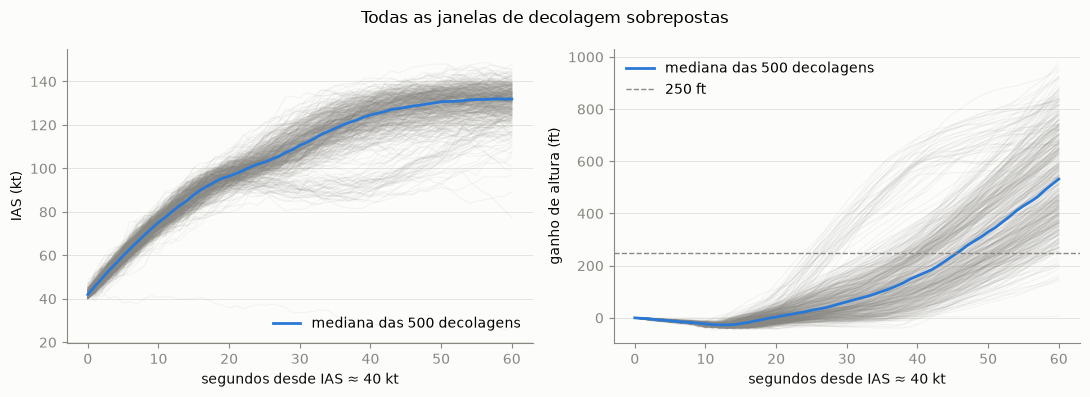

IAS em t=0: 40.0–49.0 kt | janelas que não atingem 250 ft de ganho: 13


In [136]:
t_axis = np.arange(samples_per_flight.iloc[0])
rel_alt_all = df["AltB"] - by_flight["AltB"].transform("first")
ias_wide = df.assign(t=by_flight.cumcount()).pivot(index="id_voo", columns="t", values="IAS")
alt_wide = df.assign(t=by_flight.cumcount(), rel=rel_alt_all).pivot(index="id_voo", columns="t", values="rel")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, wide, ylabel in [(axes[0], ias_wide, "IAS (kt)"), (axes[1], alt_wide, "ganho de altura (ft)")]:
    ax.plot(t_axis, wide.T.to_numpy(), color=GRAY, alpha=0.08, linewidth=0.8)
    ax.plot(t_axis, wide.median(), color=BLUE, linewidth=2, label="mediana das 500 decolagens")
    ax.set_xlabel("segundos desde IAS ≈ 40 kt")
    ax.set_ylabel(ylabel)
    ax.grid(True, axis="y")
axes[1].axhline(250, color=GRAY, linestyle="--", linewidth=1, label="250 ft")
axes[0].legend(frameon=False, loc="lower right")
axes[1].legend(frameon=False, loc="upper left")
fig.suptitle("Todas as janelas de decolagem sobrepostas")
plt.tight_layout()
plt.show()

never_250 = (alt_wide.max(axis=1) < 250).sum()
print(f"IAS em t=0: {ias_wide[0].min():.1f}–{ias_wide[0].max():.1f} kt | "
      f"janelas que não atingem 250 ft de ganho: {never_250}")

**Leitura**: todas as janelas começam entre 40 e 49 kt, o que confirma a âncora na corrida de
decolagem. A maioria chega a 250 ft de ganho de altura dentro dos 60 s. Já dá para ver alguns
traços fora do feixe, como uma janela em que a IAS **cai** no fim (decolagem abortada?). É esse
tipo de voo que o detector deve apontar sem que ninguém diga a ele o que procurar.

**Sobre a âncora**: o original ancorava no cruzamento de 250 ft AGL e usava os 70 s
**anteriores**. Aqui isso é impossível: as janelas começam já na corrida e, em mediana, o
cruzamento de 250 ft acontece cerca de 30 s depois de t = 0. A âncora nativa (IAS ≈ 40 kt) tem a
mesma função — um "ponto zero" físico comum a todas as decolagens — e foi mantida.

## 5. Limpeza e preparação

- `E1 RPM` está **100% ausente** e sai do dataset.
- Cada voo recebe o índice temporal `t_s` = posição da amostra na janela (0 … 60).
- A **detecção de sentinela** do original é mantida: um valor extremo, "grudado" (≥ 2% das
  amostras) e muito distante do resto é a assinatura de um sensor travado, e é mascarado.
- O **filtro de cobertura por janela** do original é mantido: um parâmetro com < 90% de
  amostras válidas, ou com lacuna > 5 s, descarta a janela; lacunas menores são interpoladas.

In [137]:
def detect_sentinel(values: np.ndarray) -> float | None:
    '''Valor no extremo (mín. ou máx.), com share >= 2% e a mais de 5x o IQR do resto:
    indício de saturação/preenchimento do sensor, distinto de um extremo físico genuíno.'''
    v = values[~np.isnan(values)]
    if len(v) == 0:
        return None
    for candidate in (v.min(), v.max()):
        if np.mean(v == candidate) < 0.02:
            continue
        rest = v[v != candidate]
        if len(rest) < 10:
            continue
        q75, q25 = np.percentile(rest, [75, 25])
        iqr = q75 - q25
        if iqr > 0 and abs(candidate - np.median(rest)) > 5 * iqr:
            return float(candidate)
    return None


def max_run(mask: np.ndarray) -> int:
    best = cur = 0
    for m in mask:
        cur = cur + 1 if m else 0
        best = max(best, cur)
    return best


df = df.drop(columns=["RPM"], errors="ignore")  # idempotente: a célula pode ser reexecutada
df["t_s"] = df.groupby("id_voo").cumcount()
df["REL_ALT"] = df["AltB"] - df.groupby("id_voo")["AltB"].transform("first")
if samples_per_flight.nunique() != 1:
    raise ValueError("janelas com número de amostras diferente — a vetorização exige tamanho fixo")
L = int(samples_per_flight.iloc[0])

CANDIDATE_PARAMS = ["IAS", "VSpd", "REL_ALT", "Pitch", "Roll", "NormAc", "LatAc",
                    "TORQ", "ITT", "FF", "OIL_T", "OIL_P"]

sentinels = {}
for p in CANDIDATE_PARAMS:
    sv = detect_sentinel(df[p].to_numpy(dtype=float))
    if sv is not None:
        sentinels[p] = sv
        df.loc[np.isclose(df[p], sv), p] = np.nan
print("sentinelas detectadas:", sentinels or "nenhuma")

pooled_validity = df[CANDIDATE_PARAMS].notna().mean()
low_validity = pooled_validity[pooled_validity < MIN_VALID_SHARE]
print("descartados por validade < 90%:", low_validity.round(3).to_dict() or "nenhum")
survivors = [p for p in CANDIDATE_PARAMS if p not in low_validity.index]

sentinelas detectadas: nenhuma
descartados por validade < 90%: nenhum


## 6. Engenharia e seleção de atributos

**Exclusões por decisão de projeto**, feitas antes de qualquer estatística e seguindo o mesmo
critério do original: confundidores, circularidade e redundância determinística.

In [138]:
design_exclusions = pd.DataFrame([
    ("AltB, AltMSL (absolutas)", "dependem da elevação da pista e do ajuste barométrico; entram só como ganho relativo REL_ALT"),
    ("Latitude, Longitude", "posição — identifica a pista, não o comportamento do voo (usada só como confundidor, §12)"),
    ("OAT", "condição ambiente — confundidor (testado na §12), como T1 no original"),
    ("IAS_Acceleration, Pitch_Rate, Roll_Rate", "diferenças exatas de IAS/Pitch/Roll (validado na §4)"),
    ("ITT_TORQ_RATIO", "razão determinística de ITT e TORQ"),
    ("RPM", "100% ausente"),
], columns=["coluna(s)", "motivo da exclusão"])
design_exclusions

,coluna(s),motivo da exclusão
0,"AltB, AltMSL (absolutas)",dependem da elevação da pista e do ajuste baro...
1,"Latitude, Longitude","posição — identifica a pista, não o comportame..."
2,OAT,condição ambiente — confundidor (testado na §1...
3,"IAS_Acceleration, Pitch_Rate, Roll_Rate",diferenças exatas de IAS/Pitch/Roll (validado ...
4,ITT_TORQ_RATIO,razão determinística de ITT e TORQ
5,RPM,100% ausente


**Redundância estatística**: se dois parâmetros têm |r| ≥ 0,95 ao longo de todas as amostras,
o segundo é descartado (mesma regra do original).

In [139]:
dropped_corr = []
for i, a in enumerate(survivors):
    if a in dropped_corr:
        continue
    for b in survivors[i + 1:]:
        if b in dropped_corr:
            continue
        pair = df[[a, b]].dropna()
        r = np.corrcoef(pair[a], pair[b])[0, 1]
        if abs(r) >= REDUNDANCY_R:
            print(f"descartado por redundância: {b} (r={r:.3f} com {a})")
            dropped_corr.append(b)

selected = [p for p in survivors if p not in dropped_corr]
print(f"features selecionadas ({len(selected)}):", selected)

features selecionadas (12): ['IAS', 'VSpd', 'REL_ALT', 'Pitch', 'Roll', 'NormAc', 'LatAc', 'TORQ', 'ITT', 'FF', 'OIL_T', 'OIL_P']


**Vetorização**: cada janela (61 amostras × parâmetro) é achatada num vetor
`<parâmetro>__t000 … t060`. Janelas sem cobertura suficiente são descartadas; lacunas curtas
são interpoladas linearmente.

In [140]:
wide = {p: df.pivot(index="id_voo", columns="t_s", values=p) for p in selected}
flight_ids = wide[selected[0]].index

vectors, kept_ids, n_rejected = [], [], 0
for fid in flight_ids:
    series, ok = [], True
    for p in selected:
        vals = wide[p].loc[fid].to_numpy(dtype=float)
        invalid = np.isnan(vals)
        if (1 - invalid.mean()) < MIN_VALID_SHARE or max_run(invalid) > MAX_GAP_S:
            ok = False
            break
        if invalid.any():
            idx = np.arange(L)
            vals = np.interp(idx, idx[~invalid], vals[~invalid])
        series.append(vals)
    if ok:
        vectors.append(np.concatenate(series))
        kept_ids.append(fid)
    else:
        n_rejected += 1

X = np.vstack(vectors)
FEATURE_NAMES = [f"{p}__t{t:03d}" for p in selected for t in range(L)]
P = len(selected)

first_rows = df[df["t_s"] == 0].set_index("id_voo")
lat0 = first_rows["Latitude"]
runway_split = (lat0.min() + lat0.max()) / 2   # dois modos bem separados: início da corrida em cada cabeceira
meta = pd.DataFrame({
    "id_voo": kept_ids,
    "aeronave": first_rows.loc[kept_ids, "aeronave"].to_numpy(),
    "data": first_rows.loc[kept_ids, "timestamp"].to_numpy(),
    "oat_c": df.groupby("id_voo")["OAT"].mean().loc[kept_ids].to_numpy(),
    "cabeceira": np.where(lat0.loc[kept_ids] > runway_split, "N", "S"),
})
print(f"janelas aceitas: {len(kept_ids)} / {len(flight_ids)} (rejeitadas por cobertura: {n_rejected})")
print("dimensão da matriz X:", X.shape)
print("início da corrida por cabeceira:", meta["cabeceira"].value_counts().to_dict())

janelas aceitas: 500 / 500 (rejeitadas por cobertura: 0)
dimensão da matriz X: (500, 732)
início da corrida por cabeceira: {'S': 333, 'N': 167}


## 7. Modelagem: PCA (90% de variância) + distância-K

Configuração literal do original:

1. **padronizar cada coluna** do vetor (z-score) — os parâmetros têm escalas muito diferentes
   (kt, °, lb·ft, g…);
2. reter componentes principais até **90% de variância acumulada** (**K** componentes);
3. medir, para cada voo, a **distância ao MinPts-ésimo vizinho** no espaço de K dimensões,
   com $\mathrm{MinPts} = K + 1$ (contando o próprio ponto, exatamente como o DBSCAN conta).

O pipeline fica numa função porque é reaplicado na análise de confiança (§12).

**Sobre data leakage**: não há rótulo nem alvo, e o objetivo é triar **esta** população
fechada. Ajustar escala e PCA em todos os voos é, portanto, a escolha coerente (transdutiva),
não um vazamento. O risco análogo em detecção não supervisionada é outro: a "referência de
normalidade" depender dos próprios voos avaliados. Esse risco é medido na §12 com reamostragem
e *hold-out* temporal, em que os voos são pontuados contra uma referência que **não** os contém.

In [141]:
def fit_atypicality(X_ref: np.ndarray, var_target: float = VAR_TARGET, min_samples: int | None = None) -> dict:
    '''Escala + PCA + distância ao MinPts-ésimo vizinho (incluindo o próprio ponto).'''
    scaler = StandardScaler().fit(X_ref)
    Z = scaler.transform(X_ref)
    pca = PCA(svd_solver="full", random_state=RANDOM_STATE).fit(Z)
    cum = np.cumsum(pca.explained_variance_ratio_)
    K = int(np.searchsorted(cum, var_target) + 1)
    scores = pca.transform(Z)[:, :K]
    min_samples = min_samples or K + 1
    nn = NearestNeighbors(n_neighbors=min_samples).fit(scores)
    dist, idx = nn.kneighbors(scores)
    return {"scaler": scaler, "pca": pca, "K": K, "cum": cum, "min_samples": min_samples,
            "Z": Z, "scores": scores, "nn": nn, "nbr_dist": dist, "nbr_idx": idx, "kdist": dist[:, -1]}


def score_against(model: dict, X_query: np.ndarray, in_reference: np.ndarray) -> np.ndarray:
    '''Distância-K de novos pontos contra uma referência já ajustada. Para pontos que estão na
    referência o 1º vizinho é o próprio ponto; para os de fora, usa-se um vizinho a menos —
    a mesma definição da distância-K nos dois casos.'''
    q = model["pca"].transform(model["scaler"].transform(X_query))[:, :model["K"]]
    dist, _ = model["nn"].kneighbors(q)
    return np.where(in_reference, dist[:, -1], dist[:, -2])


model = fit_atypicality(X)
K, min_samples, Xs, scores = model["K"], model["min_samples"], model["Z"], model["scores"]
kdist = model["kdist"]
kd_sorted = np.sort(kdist)

rho = min_samples / X.shape[0]
cv_kdist = kdist.std() / kdist.mean()
print(f"n={X.shape[0]}  dim={X.shape[1]}  K={K} (var. acumulada {model['cum'][K-1]:.1%})  MinPts={min_samples}")
print(f"rho = MinPts/n = {rho:.3f}   cv(distância-K) = {cv_kdist:.3f}")

n=500  dim=732  K=84 (var. acumulada 90.1%)  MinPts=85
rho = MinPts/n = 0.170   cv(distância-K) = 0.239


## 8. Detecção de anomalias: DBSCAN literal

O raio $\varepsilon$ é lido **diretamente** do percentil da distância-K para três alvos de ruído
(1%, 5%, 10%), sem otimizar para acertar a fração nominal. A diferença entre o alvo e o ruído
real é informação de diagnóstico: pontos com distância-K > ε ainda podem ser absorvidos como
**borda** de um cluster.

In [142]:
results = {}
for target in NOISE_TARGETS:
    eps = np.percentile(kdist, 100 * (1 - target))
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(scores)
    n_noise = int((labels == -1).sum())
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    results[target] = {"eps": eps, "labels": labels, "n_noise": n_noise, "n_clusters": n_clusters}
    print(f"  alvo {target:4.0%}: eps={eps:6.2f}  ruído real={n_noise / len(labels):5.1%} "
          f"({n_noise:3d} janelas)  clusters={n_clusters}")

  alvo   1%: eps= 44.32  ruído real= 0.4% (  2 janelas)  clusters=1
  alvo   5%: eps= 38.23  ruído real= 0.4% (  2 janelas)  clusters=1
  alvo  10%: eps= 34.77  ruído real= 0.8% (  4 janelas)  clusters=1


### Consistência entre rótulo binário e pontuação contínua

No DBSCAN, um ponto é **núcleo** se tiver ≥ MinPts vizinhos dentro de ε, ou seja, se
distância-K ≤ ε. Ruído é sempre não-núcleo, então **todo ruído tem distância-K > ε**. Se essa
relação falhar, rótulo e pontuação estariam medindo coisas diferentes e não poderíamos
apresentar a distância-K como "o score do detector". A célula abaixo verifica isso.

In [143]:
for target, res in results.items():
    noise = res["labels"] == -1
    non_core = kdist > res["eps"]
    assert np.all(kdist[noise] > res["eps"]), "ruído com distância-K <= eps: rótulo e score inconsistentes"
    print(f"alvo {target:4.0%}: não-núcleo={non_core.sum():3d}  ruído={noise.sum():3d}  "
          f"bordas absorvidas por cluster={int((non_core & ~noise).sum()):3d}  -> consistente")

labels_primary = results[PRIMARY_TARGET]["labels"]
eps_primary = results[PRIMARY_TARGET]["eps"]
meta["kdist"] = kdist
meta["kdist_pct"] = stats.rankdata(kdist) / len(kdist) * 100
meta["ruido_dbscan"] = labels_primary == -1
meta["candidato"] = kdist > eps_primary          # não-núcleo @ alvo primário (ver correção abaixo)
n_cand = int(meta["candidato"].sum())
print(f"\nalvo {PRIMARY_TARGET:.0%}: ruído DBSCAN = {int(meta['ruido_dbscan'].sum())} | "
      f"candidatos para triagem (não-núcleo) = {n_cand} de {len(meta)}")

alvo   1%: não-núcleo=  5  ruído=  2  bordas absorvidas por cluster=  3  -> consistente
alvo   5%: não-núcleo= 25  ruído=  2  bordas absorvidas por cluster= 23  -> consistente
alvo  10%: não-núcleo= 50  ruído=  4  bordas absorvidas por cluster= 46  -> consistente

alvo 5%: ruído DBSCAN = 2 | candidatos para triagem (não-núcleo) = 25 de 500


### Correção metodológica: lista de candidatos = pontos não-núcleo

Com a regra literal, o DBSCAN absorve quase todos os pontos não-núcleo como **borda** do único
cluster: no alvo de 5%, dos 25 voos com distância-K > ε, apenas 2 viram "ruído" (0,4% da
população). O original usava o ruído como lista de candidatos, e aqui essa lista degeneraria
para dois voos. A absorção como borda depende só de um voo cair dentro do raio de **algum**
ponto núcleo; ela não diz nada sobre o voo ser típico.

Por isso, nesta versão:

- **candidatos para triagem** = pontos **não-núcleo** no alvo de 5% (distância-K > ε). São
  exatamente os 5% nominais que o alvo pede, e a checagem acima garante que essa lista contém
  o ruído do DBSCAN;
- **ruído DBSCAN** (literal) é mantido como coluna à parte e funciona como **prioridade
  máxima** dentro da lista.

A pontuação e o raio ε continuam exatamente os do método literal; muda só o critério de corte
do rótulo binário, que passa a ser coerente com a própria pontuação.

### Lendo $\rho$ e o coeficiente de variação da distância-K

$\rho = \mathrm{MinPts}/n$ diz que fração da população a regra literal exige como vizinhança
mínima de um cluster. Com n = 500 e K na casa das dezenas, $\rho$ é alto. O **cv da distância-K**
mede o quanto essas distâncias variam entre os voos: um cv baixo significa densidade quase
uniforme. As duas coisas juntas explicam o **colapso estrutural** que aparece acima: um único
cluster e quase nenhum ruído. É o mesmo padrão diagnosticado no original, aqui ainda mais
forte, porque n é menor.
Por isso a **pontuação contínua** (distância-K) é a grandeza a reportar com confiança; o rótulo
binário depende do alvo de ruído escolhido.

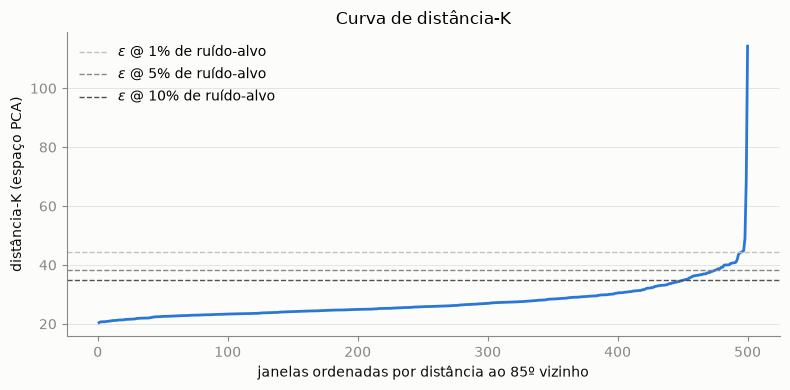

In [144]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(kd_sorted) + 1), kd_sorted, color=BLUE, linewidth=2)
palette_by_target = {0.01: "#c3c2b7", 0.05: "#898781", 0.10: "#52514e"}
for target, res in results.items():
    ax.axhline(res["eps"], color=palette_by_target[target], linestyle="--", linewidth=1,
               label=f"$\\varepsilon$ @ {target:.0%} de ruído-alvo")
ax.set_xlabel(f"janelas ordenadas por distância ao {min_samples}º vizinho")
ax.set_ylabel("distância-K (espaço PCA)")
ax.set_title("Curva de distância-K")
ax.grid(True, axis="y")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## 9. Avaliação dos resultados (sem rótulo)

Sem rótulo não há acurácia, precisão ou recall no sentido usual. Usamos duas evidências
indiretas e complementares:

**(a) Plausibilidade física.** Definimos *a priori* eventos de referência por regras simples,
no estilo de *exceedances* de monitoramento de voo, **independentes do detector**:

| regra | condição na janela |
|---|---|
| `bank` | \|Roll\| máximo > 30° |
| `perda_torque` | torque mínimo < 50% da mediana da própria janela |
| `fator_carga` | NormAc > 1,6 g ou < 0,5 g |
| `baixa_energia` | IAS final < 80 kt **ou** ganho de altura < 150 ft |

Essas regras **não são verdade de campo**: um evento de regra pode ser operacionalmente
legítimo, e uma anomalia real pode não disparar regra nenhuma. A pergunta é mais modesta:
*o detector, que nunca viu essas regras, coloca esses voos fisicamente extremos no topo da
ordenação?* Se não colocar, há motivo para desconfiar dele.

**(b) Concordância entre detectores.** Comparamos a distância-K com duas pontuações de natureza
diferente:
- **SPE** (erro de reconstrução do PCA): mede o que ficou **fora** dos K componentes. Um desvio
  localizado e curto, que ocupa pouca variância, pode ser invisível para a distância-K e
  visível no SPE;
- **Isolation Forest** sobre os vetores padronizados: um mecanismo diferente, baseado em
  partições aleatórias (`random_state` fixo).

In [145]:
flight_stats = df.groupby("id_voo").agg(
    roll_max=("Roll", lambda s: s.abs().max()), torq_min=("TORQ", "min"), torq_med=("TORQ", "median"),
    nz_max=("NormAc", "max"), nz_min=("NormAc", "min"), ias_end=("IAS", "last"), climb=("REL_ALT", "last"),
).loc[meta["id_voo"]].reset_index(drop=True)

RULES = {
    "bank": flight_stats["roll_max"] > BANK_LIMIT_DEG,
    "perda_torque": flight_stats["torq_min"] < TORQUE_DROP_FRAC * flight_stats["torq_med"],
    "fator_carga": (flight_stats["nz_max"] > NZ_HIGH) | (flight_stats["nz_min"] < NZ_LOW),
    "baixa_energia": (flight_stats["ias_end"] < IAS_END_MIN_KT) | (flight_stats["climb"] < CLIMB_MIN_FT),
}
for name, flag in RULES.items():
    meta[f"regra_{name}"] = flag.to_numpy()
RULE_COLS = [f"regra_{r}" for r in RULES]
meta["regras"] = meta[RULE_COLS].apply(lambda row: ", ".join(c[6:] for c in RULE_COLS if row[c]), axis=1)
meta["evento_ref"] = meta[RULE_COLS].any(axis=1)
print("eventos de referência por regra:", {r: int(meta[f'regra_{r}'].sum()) for r in RULES})
print(f"voos com >= 1 evento de referência: {int(meta['evento_ref'].sum())} / {len(meta)}")

eventos de referência por regra: {'bank': 9, 'perda_torque': 21, 'fator_carga': 8, 'baixa_energia': 4}
voos com >= 1 evento de referência: 30 / 500


In [146]:
pca_full = model["pca"]
Xs_hat = pca_full.inverse_transform(np.pad(scores, ((0, 0), (0, pca_full.n_components_ - K))))
meta["spe"] = ((Xs - Xs_hat) ** 2).sum(axis=1)

iforest = IsolationForest(n_estimators=500, random_state=RANDOM_STATE).fit(Xs)
meta["iforest"] = -iforest.score_samples(Xs)

SCORES = {"distância-K (principal)": "kdist", "SPE (resíduo PCA)": "spe", "Isolation Forest": "iforest"}
top_n = int(round(PRIMARY_TARGET * len(meta)))


def precision_at(score_col, k):
    return meta.nlargest(k, score_col)["evento_ref"].mean()


rows = []
for label, col in SCORES.items():
    top_set = set(meta.nlargest(top_n, col).index)
    rows.append({"pontuação": label,
                 "AUC vs eventos ref.": roc_auc_score(meta["evento_ref"], meta[col]),
                 "precisão@10": precision_at(col, 10),
                 f"precisão@{top_n}": precision_at(col, top_n),
                 "Spearman c/ dist-K": stats.spearmanr(meta[col], meta["kdist"])[0],
                 f"sobreposição top-{top_n} c/ dist-K": len(top_set & set(meta.nlargest(top_n, "kdist").index)) / top_n})
evaluation = pd.DataFrame(rows).set_index("pontuação")
print(f"taxa-base de eventos de referência: {meta['evento_ref'].mean():.1%}")
evaluation.round(3)

taxa-base de eventos de referência: 6.0%


,AUC vs eventos ref.,precisão@10,precisão@25,Spearman c/ dist-K,sobreposição top-25 c/ dist-K
pontuação,,,,,
distância-K (principal),0.867,0.4,0.28,1.000,1.0
SPE (resíduo PCA),0.690,0.2,0.12,0.384,0.0
Isolation Forest,0.814,0.3,0.28,0.944,0.8


In [147]:
per_rule_auc = pd.DataFrame({label: {r: roc_auc_score(meta[f"regra_{r}"], meta[col]) for r in RULES}
                             for label, col in SCORES.items()}).round(3)
per_rule_auc.index.name = "AUC por regra"
per_rule_auc

,distância-K (principal),SPE (resíduo PCA),Isolation Forest
AUC por regra,,,
bank,0.859,0.664,0.700
perda_torque,0.920,0.685,0.882
fator_carga,0.825,0.567,0.781
baixa_energia,0.937,0.436,0.957


In [148]:
crosstab = pd.crosstab(meta["evento_ref"].map({True: "com evento ref.", False: "sem evento ref."}),
                       meta["candidato"].map({True: f"candidato (top {PRIMARY_TARGET:.0%})", False: "normal"}))
crosstab

candidato,candidato (top 5%),normal
evento_ref,,
com evento ref.,7,23
sem evento ref.,18,452


**Leitura**

- A distância-K ordena os eventos de referência bem acima do acaso: **AUC = 0,87**. Entre os
  10 voos mais atípicos, 40% têm evento físico, e entre os 25 candidatos, 28%. A taxa-base é
  6%, então a lista concentra os eventos cerca de 4,7 vezes. Os dois voos de ruído DBSCAN têm
  evento físico.
- Mesmo assim, **23 dos 30 eventos não entram na lista**. A maioria é `perda_torque` em
  poucos segundos no fim da janela: um desvio curto ocupa pouca variância e fica diluído entre
  732 colunas. Uma AUC alta **não** garante que a lista de corte capture os eventos.
- O **Isolation Forest** concorda fortemente com a distância-K (Spearman 0,94; 80% do top 25 em
  comum): dois mecanismos diferentes chegam à mesma ordenação, o que é evidência de confiança.
- O **SPE** quase não concorda (Spearman 0,38; **nenhum** voo em comum no top 25). Ele enxerga
  o que o subespaço PCA descarta e, portanto, é um **complemento**, não um substituto: os
  voos que só o SPE aponta formam a lista de "pontos cegos" da §13.

## 10. Visualizações

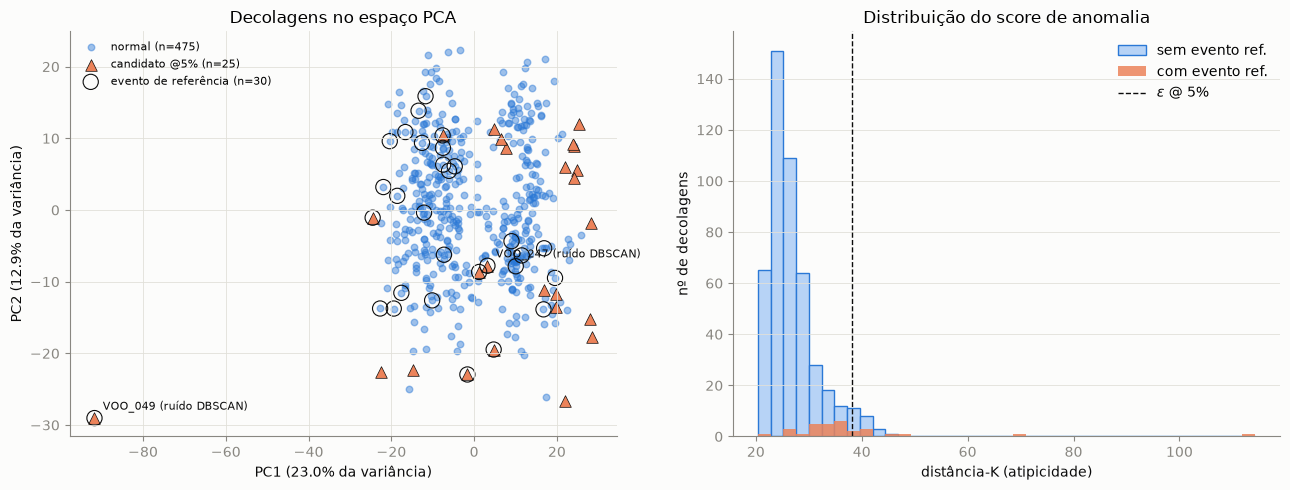

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
normal = ~meta["candidato"]
ax.scatter(scores[normal, 0], scores[normal, 1], s=22, color=BLUE, alpha=0.45, label=f"normal (n={normal.sum()})")
ax.scatter(scores[~normal, 0], scores[~normal, 1], s=70, color=CANDIDATE, marker="^", edgecolor=INK,
           linewidth=0.5, label=f"candidato @{PRIMARY_TARGET:.0%} (n={(~normal).sum()})")
ref = meta["evento_ref"].to_numpy()
ax.scatter(scores[ref, 0], scores[ref, 1], s=120, facecolor="none", edgecolor=INK, linewidth=0.8,
           label=f"evento de referência (n={ref.sum()})")
for i in np.flatnonzero(meta["ruido_dbscan"]):
    ax.annotate(f"{meta.loc[i, 'id_voo']} (ruído DBSCAN)", scores[i, :2], xytext=(6, 6),
                textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0]:.1%} da variância)")
ax.set_ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1]:.1%} da variância)")
ax.set_title("Decolagens no espaço PCA")
ax.grid(True)
ax.legend(frameon=False, loc="best", fontsize=8)

ax = axes[1]
bins = np.linspace(meta["kdist"].min(), meta["kdist"].max(), 40)
ax.hist(meta.loc[~meta["evento_ref"], "kdist"], bins=bins, color=BLUE_LIGHT, edgecolor=BLUE, label="sem evento ref.")
ax.hist(meta.loc[meta["evento_ref"], "kdist"], bins=bins, color=CANDIDATE, alpha=0.85, label="com evento ref.")
ax.axvline(eps_primary, color=INK, linestyle="--", linewidth=1, label=f"$\\varepsilon$ @ {PRIMARY_TARGET:.0%}")
ax.set_xlabel("distância-K (atipicidade)")
ax.set_ylabel("nº de decolagens")
ax.set_title("Distribuição do score de anomalia")
ax.grid(True, axis="y")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

PC1 e PC2 juntos explicam só uma fração pequena da variância, então a dispersão 2D **não** mostra
a geometria em que o DBSCAN trabalha (K dimensões). Ela serve para ilustrar, não como prova.
O histograma é mais honesto: os eventos de referência se concentram na cauda direita do score.

### O que diferencia uma decolagem normal de uma anômala?

Faixa interquartil e mediana dos voos **normais** (cinza) contra o traço de cada candidato
(laranja), para todos os parâmetros do vetor:

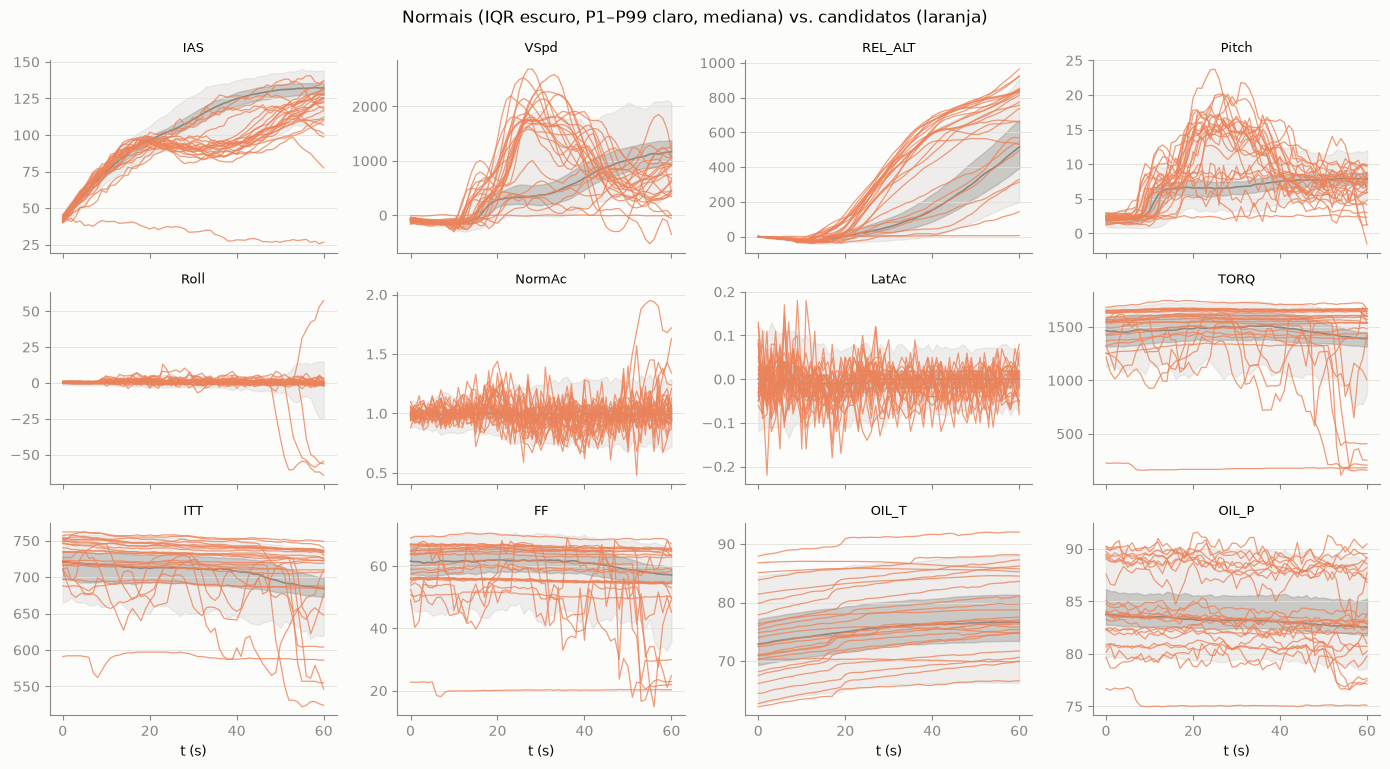

In [150]:
X3 = X.reshape(len(meta), P, L)
cand_idx = np.flatnonzero(meta["candidato"])
normal_idx = np.flatnonzero(~meta["candidato"])
n_cols = 4
fig, axes = plt.subplots(int(np.ceil(P / n_cols)), n_cols, figsize=(14, 2.6 * np.ceil(P / n_cols)), sharex=True)
for ax, (pi, p) in zip(axes.flat, enumerate(selected)):
    pop = X3[normal_idx, pi, :]
    q25, med, q75 = np.percentile(pop, [25, 50, 75], axis=0)
    q01, q99 = np.percentile(pop, [1, 99], axis=0)
    ax.fill_between(t_axis, q01, q99, color=GRAY, alpha=0.12)
    ax.fill_between(t_axis, q25, q75, color=GRAY, alpha=0.35)
    ax.plot(t_axis, med, color=GRAY, linewidth=1.2)
    for ci in cand_idx:
        ax.plot(t_axis, X3[ci, pi, :], color=CANDIDATE, linewidth=0.9, alpha=0.8)
    ax.set_title(p, fontsize=9)
    ax.grid(True, axis="y")
for ax in axes.flat[P:]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("t (s)")
fig.suptitle("Normais (IQR escuro, P1–P99 claro, mediana) vs. candidatos (laranja)")
plt.tight_layout()
plt.show()

## 11. Explicabilidade (XAI): por que uma decolagem foi considerada anômala?

### 11.1 Decomposição exata da distância-K

O score de um voo *i* é a distância euclidiana, no espaço dos K componentes, até o seu vizinho
de referência *j* (o MinPts-ésimo). Seja $V_K$ a matriz $K \times D$ das direções principais
(linhas ortonormais) e $\delta = z_i - z_j$ a diferença entre os dois vetores padronizados. Então

$$d_K^2 = \lVert V_K\,\delta \rVert^2 = \lVert V_K^\top V_K\,\delta \rVert^2 = \sum_{c=1}^{D} \big[(V_K^\top V_K\,\delta)_c\big]^2 ,$$

porque projetar de volta no espaço original preserva a norma. Cada coluna *c* (um parâmetro num
segundo) recebe uma parcela **não-negativa**, e as parcelas **somam exatamente** $d_K^2$. Somando
por parâmetro, obtemos "quanto % do score vem do torque, da rolagem…"; somando por segundo,
"em que momento da decolagem".

A escolha dessa técnica, e não de SHAP, segue a recomendação de usar um método compatível com
o modelo. O detector não é um preditor com saída a explicar, é uma **distância**. A decomposição
acima é **exata e fiel** ao score reportado, dispensa amostragem e aproximações, e não exige
biblioteca adicional (SHAP nem está instalado no ambiente). O diagnóstico por z-score do
original é mantido na §11.2 como verificação cruzada.

In [151]:
V_K = pca_full.components_[:K]
ref_neighbor = model["nbr_idx"][:, -1]
proj = (Xs - Xs[ref_neighbor]) @ V_K.T @ V_K          # (n, D): diferença projetada no subespaço K
contrib = proj ** 2                                      # parcelas por coluna; soma = kdist²
assert np.allclose(contrib.sum(axis=1), kdist ** 2), "decomposição não fecha com o score"

contrib_param = contrib.reshape(len(meta), P, L).sum(axis=2)
share_param = pd.DataFrame(contrib_param / contrib_param.sum(axis=1, keepdims=True),
                           columns=selected, index=meta["id_voo"])
print("verificação: soma das parcelas == distância-K² para todos os voos ->",
      np.allclose(contrib.sum(axis=1), kdist ** 2))


def top_drivers(i: int, k: int = 3) -> str:
    s = share_param.iloc[i].nlargest(k)
    return ", ".join(f"{p} ({v:.0%})" for p, v in s.items())

verificação: soma das parcelas == distância-K² para todos os voos -> True


voo mais atípico: VOO_049 (ANV_A) | distância-K=114.3 (percentil 100.0) | vizinho de referência: VOO_082
regras disparadas: baixa_energia


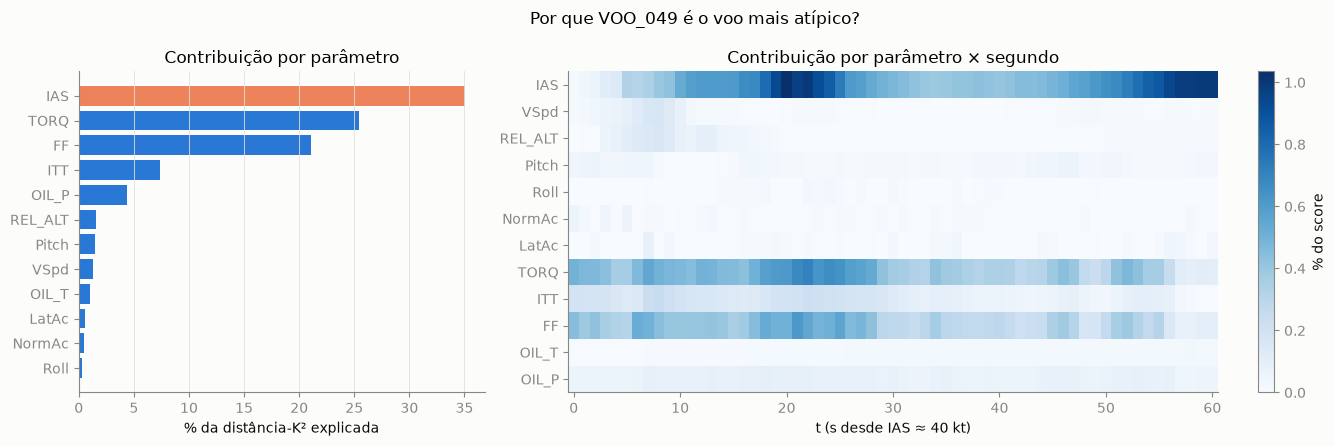

In [152]:
top_i = int(meta["kdist"].idxmax())
top = meta.loc[top_i]
print(f"voo mais atípico: {top['id_voo']} ({top['aeronave']}) | distância-K={top['kdist']:.1f} "
      f"(percentil {top['kdist_pct']:.1f}) | vizinho de referência: {meta.loc[ref_neighbor[top_i], 'id_voo']}")
print(f"regras disparadas: {top['regras'] or 'nenhuma'}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
s = share_param.iloc[top_i].sort_values()
axes[0].barh(s.index, s.values * 100, color=[CANDIDATE if v == s.max() else BLUE for v in s.values])
axes[0].set_xlabel("% da distância-K² explicada")
axes[0].set_title("Contribuição por parâmetro")
axes[0].grid(True, axis="x")

heat = contrib[top_i].reshape(P, L) / contrib[top_i].sum() * 100
im = axes[1].imshow(heat, aspect="auto", cmap="Blues", interpolation="nearest")
axes[1].set_yticks(range(P))
axes[1].set_yticklabels(selected)
axes[1].set_xlabel("t (s desde IAS ≈ 40 kt)")
axes[1].set_title("Contribuição por parâmetro × segundo")
fig.colorbar(im, ax=axes[1], label="% do score")
fig.suptitle(f"Por que {top['id_voo']} é o voo mais atípico?")
plt.tight_layout()
plt.show()

### 11.2 Verificação cruzada: diagnóstico por z-score (método do original)

O original explicava o candidato pelo **máximo |z-score|** de cada parâmetro na janela. Esse
diagnóstico é intuitivo, mas não está ligado matematicamente ao score. Se os dois métodos
apontam os mesmos parâmetros, a explicação ganha credibilidade; onde divergem, vale a
explicação exata.

Um cuidado: o z-score é calculado **coluna a coluna** (parâmetro × segundo). Em segundos em que
um parâmetro quase não varia entre voos (por exemplo, IAS em t = 0, fixada pela âncora), um
pequeno desvio vira um z enorme. O máximo |z| pode então exagerar parâmetros de baixa
variância. A decomposição exata não sofre desse problema, porque só conta o desvio que o PCA
efetivamente usa.

In [153]:
z_top = Xs[top_i].reshape(P, L)
cross_check = pd.DataFrame({
    "parte_do_score_%": share_param.iloc[top_i] * 100,
    "max_abs_z": np.max(np.abs(z_top), axis=1),
    "media_abs_z": np.mean(np.abs(z_top), axis=1),
}, index=selected).sort_values("parte_do_score_%", ascending=False)
rho_methods = stats.spearmanr(cross_check["parte_do_score_%"], cross_check["max_abs_z"])[0]
print(f"Spearman entre as ordenações (decomposição exata vs. max |z|): {rho_methods:.2f}")
cross_check.round(2)

Spearman entre as ordenações (decomposição exata vs. max |z|): 0.93


,parte_do_score_%,max_abs_z,media_abs_z
IAS,35.08,12.11,8.97
TORQ,25.40,8.71,7.69
FF,21.10,7.67,6.58
ITT,7.40,5.98,4.57
OIL_P,4.36,3.48,3.30
REL_ALT,1.52,5.58,1.98
Pitch,1.44,3.77,2.25
VSpd,1.33,5.47,2.24
OIL_T,1.04,1.37,1.09
LatAc,0.55,2.26,0.71


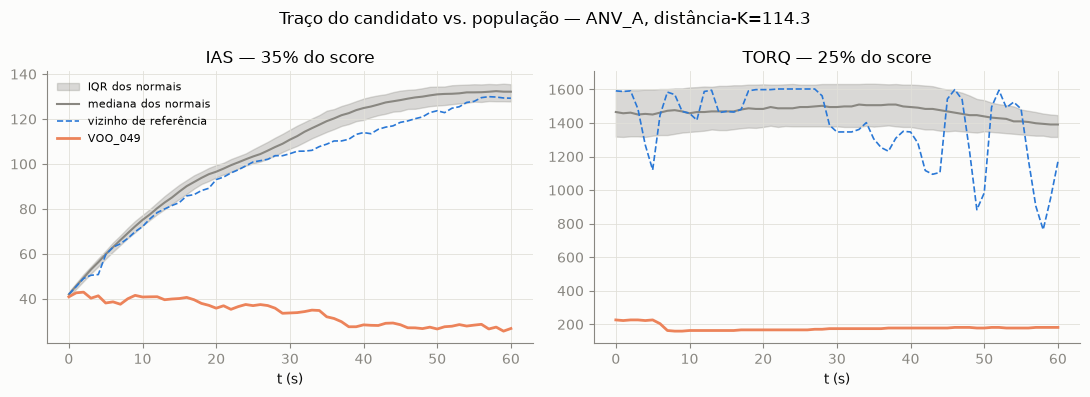

In [154]:
top2 = share_param.iloc[top_i].nlargest(2).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, p in zip(axes, top2):
    pi = selected.index(p)
    pop = X3[normal_idx, pi, :]
    q25, med, q75 = np.percentile(pop, [25, 50, 75], axis=0)
    ax.fill_between(t_axis, q25, q75, color=GRAY, alpha=0.3, label="IQR dos normais")
    ax.plot(t_axis, med, color=GRAY, linewidth=1.5, label="mediana dos normais")
    ax.plot(t_axis, X3[ref_neighbor[top_i], pi, :], color=BLUE, linewidth=1.2, linestyle="--", label="vizinho de referência")
    ax.plot(t_axis, X3[top_i, pi, :], color=CANDIDATE, linewidth=2, label=top["id_voo"])
    ax.set_title(f"{p} — {share_param.iloc[top_i][p]:.0%} do score")
    ax.set_xlabel("t (s)")
    ax.grid(True)
axes[0].legend(frameon=False, loc="best", fontsize=8)
fig.suptitle(f"Traço do candidato vs. população — {top['aeronave']}, distância-K={top['kdist']:.1f}")
plt.tight_layout()
plt.show()

### 11.3 Explicação global: que parâmetros movem a lista de candidatos?

A mesma decomposição, agregada: participação média de cada parâmetro no score dos candidatos
contra a dos voos normais, e o "mapa de explicações" candidato a candidato.

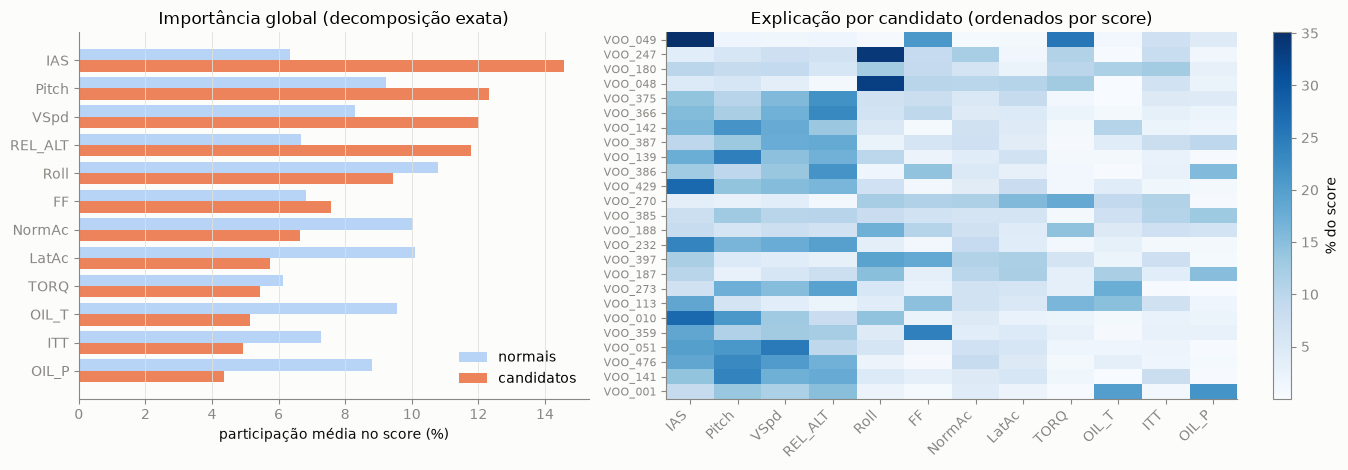

,candidatos,normais,razão
IAS,0.146,0.063,2.303
Pitch,0.123,0.092,1.339
VSpd,0.120,0.083,1.452
REL_ALT,0.118,0.067,1.770
Roll,0.094,0.108,0.874
FF,0.076,0.068,1.109
NormAc,0.066,0.100,0.662
LatAc,0.057,0.101,0.567
TORQ,0.054,0.061,0.890
OIL_T,0.052,0.096,0.539


In [155]:
global_share = pd.DataFrame({
    "candidatos": share_param[meta["candidato"].to_numpy()].mean(),
    "normais": share_param[~meta["candidato"].to_numpy()].mean(),
}).sort_values("candidatos", ascending=False)
global_share["razão"] = global_share["candidatos"] / global_share["normais"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
y = np.arange(P)
axes[0].barh(y - 0.2, global_share["normais"] * 100, height=0.4, color=BLUE_LIGHT, label="normais")
axes[0].barh(y + 0.2, global_share["candidatos"] * 100, height=0.4, color=CANDIDATE, label="candidatos")
axes[0].set_yticks(y)
axes[0].set_yticklabels(global_share.index)
axes[0].invert_yaxis()
axes[0].set_xlabel("participação média no score (%)")
axes[0].set_title("Importância global (decomposição exata)")
axes[0].legend(frameon=False)
axes[0].grid(True, axis="x")

cand_share = share_param[meta["candidato"].to_numpy()].loc[:, global_share.index]
cand_share = cand_share.loc[meta.loc[meta["candidato"]].sort_values("kdist", ascending=False)["id_voo"]]
im = axes[1].imshow(cand_share.to_numpy() * 100, aspect="auto", cmap="Blues")
axes[1].set_xticks(range(P))
axes[1].set_xticklabels(cand_share.columns, rotation=45, ha="right")
axes[1].set_yticks(range(len(cand_share)))
axes[1].set_yticklabels(cand_share.index, fontsize=8)
axes[1].set_title("Explicação por candidato (ordenados por score)")
fig.colorbar(im, ax=axes[1], label="% do score")
plt.tight_layout()
plt.show()
global_share.round(3)

## 12. Análise de confiança

Uma lista de triagem sem rótulo só merece confiança se (i) não mudar muito quando mudam os
dados ou as escolhas arbitrárias do método e (ii) não puder ser explicada por um fator trivial
(aeronave, pista, clima). Testamos as duas coisas.

### 12.1 Concentração por aeronave

Mesma análise do original: teste exato de Fisher por aeronave (candidatos vs. resto), com
correção de Holm para comparações múltiplas, e Kruskal-Wallis sobre o score contínuo, que usa
os 500 voos e não só os candidatos.

In [156]:
def holm_adjust(pvalues) -> np.ndarray:
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1.0)
    out = np.empty_like(p)
    out[order] = adjusted
    return out


def candidate_concentration_by(meta_df, group_col, candidate_col="candidato", score_col="kdist"):
    '''Fisher unilateral (excesso de candidatos no grupo vs. resto) + mediana do score; Holm.'''
    n_total, k_total = len(meta_df), int(meta_df[candidate_col].sum())
    rows = []
    for g, sub in meta_df.groupby(group_col):
        n_g, k_g = len(sub), int(sub[candidate_col].sum())
        table = [[k_g, n_g - k_g], [k_total - k_g, (n_total - n_g) - (k_total - k_g)]]
        rows.append({group_col: g, "n": n_g, "candidatos": k_g, "taxa": k_g / n_g,
                     "score_mediano": sub[score_col].median(),
                     "p_fisher": stats.fisher_exact(table, alternative="greater")[1]})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm_adjust(out["p_fisher"])
    return out.sort_values("p_fisher").reset_index(drop=True)


by_aircraft = candidate_concentration_by(meta, "aeronave")
h_stat, p_kw = stats.kruskal(*[sub["kdist"] for _, sub in meta.groupby("aeronave")])
print(f"taxa de candidatos na população: {meta['candidato'].mean():.1%} ({n_cand}/{len(meta)})")
print(f"Kruskal-Wallis (distância-K ~ aeronave): H={h_stat:.2f}  p={p_kw:.3f}")
by_aircraft.style.format({"taxa": "{:.1%}", "score_mediano": "{:.1f}", "p_fisher": "{:.3f}", "p_holm": "{:.3f}"})

taxa de candidatos na população: 5.0% (25/500)
Kruskal-Wallis (distância-K ~ aeronave): H=99.93  p=0.000


,aeronave,n,candidatos,taxa,score_mediano,p_fisher,p_holm
0,ANV_H,50,7,14.0%,32.1,0.008,0.077
1,ANV_A,50,4,8.0%,25.3,0.233,1.000
2,ANV_C,50,4,8.0%,27.6,0.233,1.000
3,ANV_D,50,3,6.0%,25.2,0.466,1.000
4,ANV_E,50,2,4.0%,24.4,0.736,1.000
5,ANV_F,50,2,4.0%,24.3,0.736,1.000
6,ANV_B,50,1,2.0%,24.7,0.933,1.000
7,ANV_I,50,1,2.0%,27.0,0.933,1.000
8,ANV_J,50,1,2.0%,24.2,0.933,1.000
9,ANV_G,50,0,0.0%,25.8,1.000,1.000


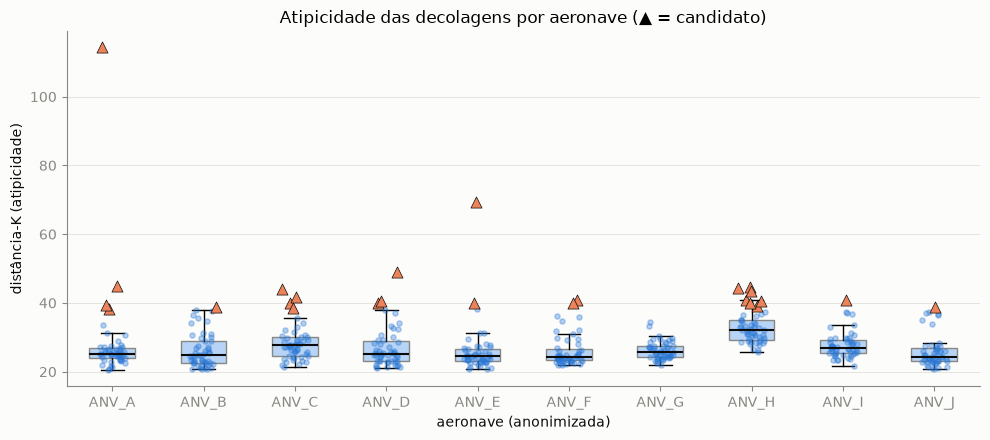

In [157]:
fig, ax = plt.subplots(figsize=(10, 4.5))
aircraft = sorted(meta["aeronave"].unique())
bp = ax.boxplot([meta.loc[meta["aeronave"] == a, "kdist"] for a in aircraft], positions=range(len(aircraft)),
                widths=0.5, showfliers=False, patch_artist=True)
for box in bp["boxes"]:
    box.set(facecolor=BLUE_LIGHT, edgecolor=GRAY, linewidth=1)
for med in bp["medians"]:
    med.set(color=INK, linewidth=1.5)
jitter_rng = np.random.default_rng(RANDOM_STATE)
for i, a in enumerate(aircraft):
    sub = meta[meta["aeronave"] == a]
    for is_cand, style in [(False, dict(s=14, color=BLUE, alpha=0.35, zorder=2)),
                           (True, dict(s=64, color=CANDIDATE, marker="^", edgecolor=INK, linewidth=0.5, zorder=3))]:
        pts = sub[sub["candidato"] == is_cand]
        ax.scatter(i + jitter_rng.uniform(-0.15, 0.15, len(pts)), pts["kdist"], **style)
ax.set_xticks(range(len(aircraft)))
ax.set_xticklabels(aircraft)
ax.set_xlabel("aeronave (anonimizada)")
ax.set_ylabel("distância-K (atipicidade)")
ax.set_title("Atipicidade das decolagens por aeronave (▲ = candidato)")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

### 12.2 O efeito de aeronave é comportamento de voo ou nível de base?

Uma diferença forte entre aeronaves no score contínuo tem duas leituras muito diferentes:

- algumas aeronaves têm **mais decolagens atípicas** (hipótese de evento);
- cada aeronave tem um **nível de base próprio** em alguns sensores (temperatura e pressão do
  óleo, calibração de torque…), e o detector mede em parte "o quanto esta cauda difere da frota"
  (hipótese de nível de base).

Para separar as duas, medimos quanto da variância da **média por voo** de cada parâmetro é
explicada pela aeronave (η²). Em seguida, recalculamos o detector **centrando cada aeronave na
própria média** (variante intra-aeronave): se a diferença entre caudas sumir e os eventos de
referência continuarem no topo, o efeito era de nível de base.

In [158]:
flight_means = pd.DataFrame(X3.mean(axis=2), columns=selected)
flight_means["aeronave"] = meta["aeronave"].to_numpy()


def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    grand = values.mean()
    between = values.groupby(groups).agg(lambda g: len(g) * (g.mean() - grand) ** 2).sum()
    return between / ((values - grand) ** 2).sum()


aircraft_effect = pd.Series({p: eta_squared(flight_means[p], flight_means["aeronave"]) for p in selected},
                            name="η² (aeronave → média por voo)").sort_values(ascending=False)
aircraft_effect.to_frame().round(3).T

,OIL_T,OIL_P,FF,TORQ,LatAc,VSpd,REL_ALT,ITT,Pitch,Roll,IAS,NormAc
η² (aeronave → média por voo),0.759,0.706,0.481,0.335,0.31,0.27,0.191,0.139,0.136,0.134,0.114,0.028


In [159]:
X_centered = X - pd.DataFrame(X).groupby(meta["aeronave"].to_numpy()).transform("mean").to_numpy()
centered_model = fit_atypicality(X_centered)
meta["kdist_intra"] = centered_model["kdist"]
h_intra, p_intra = stats.kruskal(*[sub["kdist_intra"] for _, sub in meta.groupby("aeronave")])
top_intra = set(meta.nlargest(top_n, "kdist_intra").index)

aircraft_comparison = pd.DataFrame({
    "principal (frota)": {"K": K, "Kruskal H (aeronave)": h_stat, "p Kruskal": p_kw,
                          "AUC vs eventos ref.": roc_auc_score(meta["evento_ref"], meta["kdist"]),
                          f"precisão@{top_n}": precision_at("kdist", top_n)},
    "intra-aeronave": {"K": centered_model["K"], "Kruskal H (aeronave)": h_intra, "p Kruskal": p_intra,
                       "AUC vs eventos ref.": roc_auc_score(meta["evento_ref"], meta["kdist_intra"]),
                       f"precisão@{top_n}": precision_at("kdist_intra", top_n)},
}).T
print(f"Spearman(principal, intra-aeronave) = {stats.spearmanr(meta['kdist'], meta['kdist_intra'])[0]:.3f} | "
      f"sobreposição top-{top_n} = {len(top_intra & set(meta.nlargest(top_n, 'kdist').index)) / top_n:.0%}")
aircraft_comparison.style.format("{:.3f}").format("{:.0f}", subset=["K"])

Spearman(principal, intra-aeronave) = 0.751 | sobreposição top-25 = 72%


,K,Kruskal H (aeronave),p Kruskal,AUC vs eventos ref.,precisão@25
principal (frota),84,99.929,0.000,0.867,0.280
intra-aeronave,89,47.776,0.000,0.844,0.320


**Leitura**

- A aeronave explica **76%** da variância da temperatura média do óleo e **71%** da pressão
  média por voo; para `FF`, 48%. Esses parâmetros funcionam como uma "assinatura" de cada cauda
  (motor, sensor ou calibração), estável de voo para voo.
- Centrar por aeronave reduz a diferença entre caudas no score pela metade (**H de 99,9 para
  47,8**), mas ela continua significativa. Parte do efeito, portanto, é **comportamento**: a
  `ANV_H`, por exemplo, tem ganho de altura mediano de ~640 ft em 60 s, contra ~530 ft da frota,
  e concentra candidatos do perfil de subida íngreme.
- A capacidade de ordenar eventos físicos praticamente não muda (AUC 0,87 → 0,84; precisão@25
  0,28 → 0,32), e 72% do top 25 é o mesmo nas duas versões.

**Consequência para a confiança**: a concentração em `ANV_H` (7/25 candidatos, Fisher
p = 0,008) **não sobrevive à correção de Holm** (p = 0,077) e é, em parte, efeito de nível de
base. Ela é um gatilho para investigar a operação dessa cauda, não evidência de defeito. As
diferenças de nível de óleo entre caudas são um achado **de frota**, a checar separadamente em
manutenção (calibração ou saúde do motor), e não uma anomalia de decolagem.

### 12.3 Confundidores: pista e temperatura

Um "confundidor" é uma explicação mais simples para o mesmo resultado. O original testava carga
externa, que não existe neste dataset. Aqui testamos dois fatores disponíveis que mudam a
física da decolagem sem indicar problema algum:

- **cabeceira de pista**: a latitude no início da corrida tem dois modos bem separados, que
  correspondem às duas cabeceiras e, portanto, a sentidos opostos de decolagem (vento, rampa);
- **temperatura externa (OAT)**: ar mais quente reduz desempenho, o que alonga a corrida e
  diminui a razão de subida.

In [160]:
by_runway = meta.groupby("cabeceira").agg(n=("kdist", "size"), candidatos=("candidato", "sum"),
                                          score_mediano=("kdist", "median"))
u_stat, p_runway = stats.mannwhitneyu(*[sub["kdist"] for _, sub in meta.groupby("cabeceira")])
p_runway_fisher = stats.fisher_exact(pd.crosstab(meta["cabeceira"], meta["candidato"]))[1]
rho_oat, p_oat = stats.spearmanr(meta["oat_c"], meta["kdist"])
print(by_runway, "\n")
print(f"cabeceira -> score:     Mann-Whitney p={p_runway:.3f} | candidatos (Fisher bilateral) p={p_runway_fisher:.3f}")
print(f"OAT -> score:           Spearman rho={rho_oat:.3f}  p={p_oat:.3f}")
print(f"OAT dos candidatos vs. normais (mediana): {meta.loc[meta['candidato'], 'oat_c'].median():.1f} °C vs. "
      f"{meta.loc[~meta['candidato'], 'oat_c'].median():.1f} °C")

             n  candidatos  score_mediano
cabeceira                                
N          167          11      25.835173
S          333          14      25.788830 

cabeceira -> score:     Mann-Whitney p=0.666 | candidatos (Fisher bilateral) p=0.279
OAT -> score:           Spearman rho=0.052  p=0.246
OAT dos candidatos vs. normais (mediana): 27.3 °C vs. 27.0 °C


### 12.4 Estabilidade por reamostragem

Repetimos o pipeline inteiro (escala → PCA com 90% → K → MinPts → distância-K) em
**50 subamostras de 80%** dos voos. Em cada rodada, **todos** os 500 voos são pontuados contra a
referência ajustada naquela subamostra; os ~100 voos que ficaram de fora são avaliados contra
uma referência que não os contém. Para cada voo registramos com que frequência ele fica entre os
5% mais atípicos. Essa **frequência de seleção** é uma medida direta de confiança por candidato:
um voo que aparece no topo em 95% das rodadas é um achado robusto; um que aparece em 30%
depende de detalhes da amostra.

In [161]:
boot_rng = np.random.default_rng(RANDOM_STATE)
n_sub = int(BOOTSTRAP_FRAC * len(X))
top_hits = np.zeros(len(X))
boot_rho, boot_K = [], []
for _ in range(N_BOOTSTRAP):
    sub_idx = boot_rng.choice(len(X), size=n_sub, replace=False)
    in_ref = np.zeros(len(X), dtype=bool)
    in_ref[sub_idx] = True
    boot_model = fit_atypicality(X[sub_idx])
    boot_scores = score_against(boot_model, X, in_ref)
    top_hits[np.argsort(boot_scores)[-top_n:]] += 1
    boot_rho.append(stats.spearmanr(boot_scores, kdist)[0])
    boot_K.append(boot_model["K"])

meta["freq_top5"] = top_hits / N_BOOTSTRAP
print(f"K nas rodadas: {min(boot_K)}–{max(boot_K)} (original {K})")
print(f"Spearman(score da rodada, score original): mediana={np.median(boot_rho):.3f}  "
      f"mín={np.min(boot_rho):.3f}")
print(f"candidatos com frequência de seleção >= 80%: "
      f"{int((meta.loc[meta['candidato'], 'freq_top5'] >= 0.8).sum())} de {n_cand} | "
      f"<= 50%: {int((meta.loc[meta['candidato'], 'freq_top5'] <= 0.5).sum())}")

K nas rodadas: 77–80 (original 84)
Spearman(score da rodada, score original): mediana=0.984  mín=0.980
candidatos com frequência de seleção >= 80%: 23 de 25 | <= 50%: 0


### 12.5 Sensibilidade às escolhas do método

A fração de variância (90%) e a regra MinPts = K + 1 são escolhas de configuração. Recalculamos
o score com alternativas razoáveis e medimos o quanto a ordenação e o top 5% mudam em relação
à configuração principal.

In [162]:
variants = {"var 80%": dict(var_target=0.80), "var 95%": dict(var_target=0.95),
            "MinPts = 10": dict(min_samples=10), "MinPts = 2K+1": dict(min_samples=2 * K + 1)}
base_top = set(np.argsort(kdist)[-top_n:])
sens_rows = []
for name, kwargs in variants.items():
    v = fit_atypicality(X, **kwargs)
    sens_rows.append({"variante": name, "K": v["K"], "MinPts": v["min_samples"],
                      "Spearman c/ principal": stats.spearmanr(v["kdist"], kdist)[0],
                      f"sobreposição top-{top_n}": len(base_top & set(np.argsort(v["kdist"])[-top_n:])) / top_n,
                      "AUC vs eventos ref.": roc_auc_score(meta["evento_ref"], v["kdist"])})
sensitivity = pd.DataFrame(sens_rows).set_index("variante")
sensitivity.round(3)

,K,MinPts,Spearman c/ principal,sobreposição top-25,AUC vs eventos ref.
variante,,,,,
var 80%,36,37,0.949,0.92,0.845
var 95%,128,129,0.989,1.00,0.870
MinPts = 10,84,10,0.881,0.72,0.890
MinPts = 2K+1,84,169,0.972,0.96,0.866


### 12.6 *Hold-out* temporal

Ajustamos a referência de normalidade só nos **70% de voos mais antigos** e pontuamos os
**30% mais recentes** como dados novos, que é como o detector seria usado em operação. Se a
população fosse estável no tempo, cerca de 5% dos voos novos passariam do percentil 95 da
referência. Uma fração muito maior indicaria deriva (sazonalidade, mudança de operação), e a
referência teria de ser recalibrada periodicamente.

In [163]:
order = np.argsort(meta["data"].to_numpy())
n_hold = int(round(HOLDOUT_FRAC * len(X)))
ref_idx, hold_idx = order[:-n_hold], order[-n_hold:]
cutoff = meta["data"].iloc[hold_idx].min()

time_model = fit_atypicality(X[ref_idx])
in_ref = np.zeros(len(X), dtype=bool)
in_ref[ref_idx] = True
time_scores = score_against(time_model, X, in_ref)
p95_ref = np.percentile(time_scores[ref_idx], 95)
frac_above = (time_scores[hold_idx] > p95_ref).mean()
_, p_shift = stats.mannwhitneyu(time_scores[hold_idx], time_scores[ref_idx])
held_events = meta["evento_ref"].to_numpy()[hold_idx]

print(f"referência: {len(ref_idx)} voos até {cutoff:%Y-%m-%d} | hold-out: {n_hold} voos a partir dessa data")
print(f"hold-out acima do P95 da referência: {frac_above:.1%} (esperado ~5% sob estabilidade)")
print(f"deslocamento de distribuição (Mann-Whitney): p={p_shift:.3f}")
if held_events.any() and not held_events.all():
    print(f"AUC vs eventos de referência no hold-out: {roc_auc_score(held_events, time_scores[hold_idx]):.3f} "
          f"({held_events.sum()} eventos)")

referência: 350 voos até 2025-02-24 | hold-out: 150 voos a partir dessa data
hold-out acima do P95 da referência: 8.0% (esperado ~5% sob estabilidade)
deslocamento de distribuição (Mann-Whitney): p=0.001
AUC vs eventos de referência no hold-out: 0.706 (9 eventos)


## 13. Exemplos de anomalias detectadas: cartões de triagem

A tabela reúne, para os voos mais atípicos, o que um revisor precisa para decidir onde olhar
primeiro:

- **score** e **percentil**: quanto o voo é atípico;
- **ruido_dbscan / candidato**: se o DBSCAN literal o marcou como ruído (prioridade máxima) e
  se ele está entre os não-núcleo @5%;
- **freq_top5**: com que frequência ele fica no topo sob reamostragem (confiança);
- **SPE_pct / IF_pct**: se os detectores alternativos concordam;
- **regras**: se há um evento físico simples que já explique o sinal;
- **principais_drivers**: que parâmetros respondem pela maior parte do score, pela decomposição exata.

In [164]:
meta["spe_pct"] = stats.rankdata(meta["spe"]) / len(meta) * 100
meta["iforest_pct"] = stats.rankdata(meta["iforest"]) / len(meta) * 100
meta["principais_drivers"] = [top_drivers(i) for i in range(len(meta))]

triage_cols = ["id_voo", "aeronave", "kdist", "kdist_pct", "ruido_dbscan", "candidato", "freq_top5",
               "spe_pct", "iforest_pct", "regras", "principais_drivers"]
triage = meta.sort_values("kdist", ascending=False).head(15)[triage_cols].reset_index(drop=True)
triage.style.format({"kdist": "{:.1f}", "kdist_pct": "{:.1f}", "freq_top5": "{:.0%}",
                     "spe_pct": "{:.0f}", "iforest_pct": "{:.0f}"})

,id_voo,aeronave,kdist,kdist_pct,ruido_dbscan,candidato,freq_top5,spe_pct,iforest_pct,regras,principais_drivers
0,VOO_049,ANV_A,114.3,100.0,True,True,100%,1,100,baixa_energia,"IAS (35%), TORQ (25%), FF (21%)"
1,VOO_247,ANV_E,69.4,99.8,True,True,100%,5,100,"bank, perda_torque, fator_carga","Roll (34%), NormAc (12%), TORQ (11%)"
2,VOO_180,ANV_D,49.0,99.6,False,True,100%,57,98,"bank, perda_torque, baixa_energia","ITT (13%), Roll (12%), OIL_T (12%)"
3,VOO_048,ANV_A,44.9,99.4,False,True,100%,80,83,"bank, perda_torque, fator_carga","Roll (33%), TORQ (13%), LatAc (10%)"
4,VOO_375,ANV_H,44.5,99.2,False,True,100%,67,99,,"REL_ALT (22%), VSpd (16%), IAS (14%)"
5,VOO_366,ANV_H,44.3,99.0,False,True,100%,79,100,,"REL_ALT (23%), VSpd (17%), IAS (15%)"
6,VOO_142,ANV_C,44.0,98.8,False,True,100%,90,99,,"Pitch (21%), VSpd (18%), IAS (16%)"
7,VOO_387,ANV_H,43.5,98.6,False,True,100%,70,98,,"REL_ALT (18%), VSpd (18%), Pitch (13%)"
8,VOO_139,ANV_C,41.8,98.4,False,True,100%,68,98,,"Pitch (24%), IAS (18%), REL_ALT (17%)"
9,VOO_386,ANV_H,40.9,98.2,False,True,100%,62,98,,"REL_ALT (21%), OIL_P (16%), FF (14%)"


### Que tipo de desvio compõe a lista?

Os gráficos da §10 mostram que boa parte dos candidatos **sem** evento de regra segue um mesmo
padrão coerente: rotação mais cedo, pitch de 15–20°, razão de subida perto de 2000 ft/min e IAS
estabilizada em ~95 kt. Isso tem cara de **técnica de subida íngreme** (procedimento
operacional), não de falha. A classificação abaixo é **descritiva e pós-hoc**: o limiar de pitch
foi escolhido olhando os gráficos e **não** deve ser usado como regra de avaliação.

In [165]:
STEEP_PITCH_DEG = 15.0   # pós-hoc, só para descrever a lista (não é regra de referência)
meta["perfil_ingreme"] = X3[:, selected.index("Pitch"), :].max(axis=1) > STEEP_PITCH_DEG
meta["tipo_desvio"] = np.select([meta["evento_ref"], meta["perfil_ingreme"]],
                                ["evento físico (regra)", "perfil de subida íngreme"], "outro desvio")
composition = pd.crosstab(meta["tipo_desvio"], meta["candidato"].map({True: "candidatos", False: "demais"}))
composition["% dos candidatos"] = (composition["candidatos"] / composition["candidatos"].sum() * 100).round(0)
composition["% do tipo que vira candidato"] = (composition["candidatos"] / composition.sum(axis=1) * 100).round(0)
composition

candidato,candidatos,demais,% dos candidatos,% do tipo que vira candidato
tipo_desvio,,,,
evento físico (regra),7,23,28.0,12.0
outro desvio,3,433,12.0,1.0
perfil de subida íngreme,15,19,60.0,16.0


Voos em que **SPE e/ou regras** apontam um evento, mas a distância-K não coloca no topo, formam
a segunda lista, a dos "pontos cegos" do detector principal:

In [166]:
blind = meta[(meta["evento_ref"] | (meta["spe_pct"] >= 100 * (1 - PRIMARY_TARGET))) & ~meta["candidato"]]
blind.sort_values("spe", ascending=False)[["id_voo", "aeronave", "kdist_pct", "spe_pct", "iforest_pct",
                                           "regras", "principais_drivers"]].head(10).reset_index(drop=True) \
     .style.format({"kdist_pct": "{:.1f}", "spe_pct": "{:.0f}", "iforest_pct": "{:.0f}"})

,id_voo,aeronave,kdist_pct,spe_pct,iforest_pct,regras,principais_drivers
0,VOO_406,ANV_I,69.6,100,86,,"Roll (19%), LatAc (18%), NormAc (16%)"
1,VOO_064,ANV_B,54.0,100,44,,"OIL_P (27%), Roll (12%), Pitch (11%)"
2,VOO_405,ANV_I,68.0,100,67,,"OIL_T (30%), LatAc (11%), NormAc (10%)"
3,VOO_370,ANV_H,91.6,99,91,perda_torque,"FF (20%), OIL_T (17%), Roll (12%)"
4,VOO_436,ANV_I,76.4,99,88,baixa_energia,"OIL_P (16%), NormAc (14%), ITT (11%)"
5,VOO_403,ANV_I,69.2,99,60,,"OIL_P (27%), LatAc (12%), IAS (11%)"
6,VOO_236,ANV_E,67.4,99,74,,"NormAc (18%), Roll (16%), LatAc (14%)"
7,VOO_082,ANV_B,60.6,99,70,,"LatAc (21%), NormAc (16%), Roll (12%)"
8,VOO_391,ANV_H,84.4,98,81,,"OIL_P (20%), FF (18%), REL_ALT (13%)"
9,VOO_361,ANV_H,86.2,98,90,,"FF (31%), OIL_P (28%), NormAc (8%)"


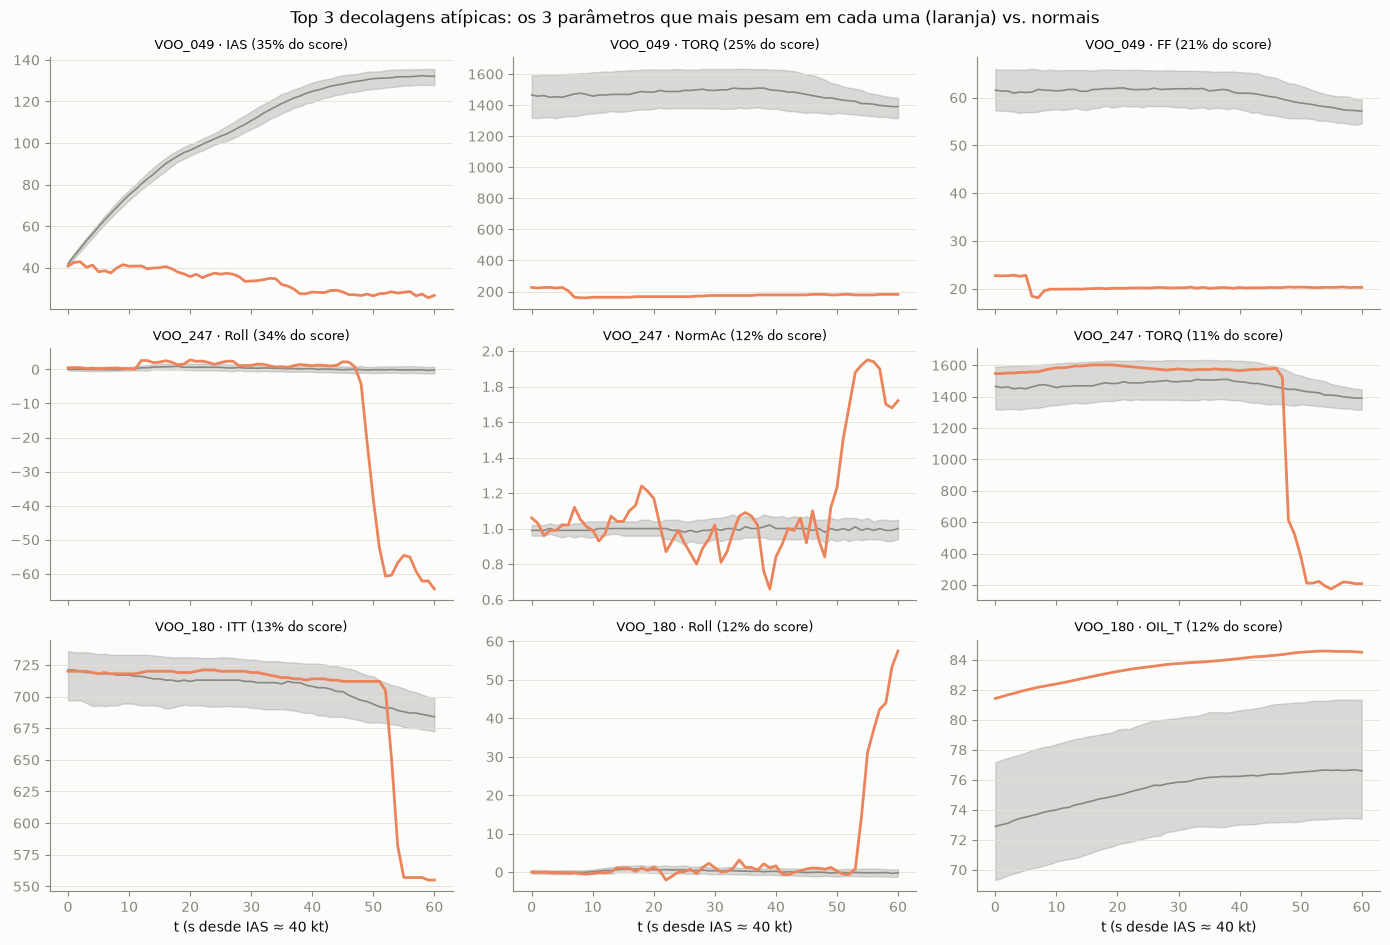

In [167]:
examples = meta.sort_values("kdist", ascending=False).head(3).index.tolist()
fig, axes = plt.subplots(len(examples), 3, figsize=(14, 3.2 * len(examples)), sharex=True)
for row, i in zip(axes, examples):
    drivers = share_param.iloc[i].nlargest(3)
    for ax, (p, share) in zip(row, drivers.items()):
        pi = selected.index(p)
        pop = X3[normal_idx, pi, :]
        q25, med, q75 = np.percentile(pop, [25, 50, 75], axis=0)
        ax.fill_between(t_axis, q25, q75, color=GRAY, alpha=0.3)
        ax.plot(t_axis, med, color=GRAY, linewidth=1.2)
        ax.plot(t_axis, X3[i, pi, :], color=CANDIDATE, linewidth=2)
        ax.set_title(f"{meta.loc[i, 'id_voo']} · {p} ({share:.0%} do score)", fontsize=9)
        ax.grid(True, axis="y")
for ax in axes[-1]:
    ax.set_xlabel("t (s desde IAS ≈ 40 kt)")
fig.suptitle("Top 3 decolagens atípicas: os 3 parâmetros que mais pesam em cada uma (laranja) vs. normais")
plt.tight_layout()
plt.show()

## 14. Conclusões

**O que o detector encontra.** Com os dados reais (500 decolagens, 10 aeronaves), o pipeline
literal PCA (K = 84 componentes, 90% da variância) + distância-K produz uma lista de triagem de
25 voos (5%). Ela tem três tipos de desvio:

| tipo | candidatos | exemplo | leitura |
|---|---|---|---|
| evento físico (regra) | 7 (28%) | `VOO_247`: rolagem a −64°, torque de ~1550 para ~200 lb·ft e 1,95 g no fim da janela | prioridade máxima para revisão |
| perfil de subida íngreme | 15 (60%) | `VOO_375`, `VOO_366`: pitch de 15–20° e ~2000 ft/min | provável técnica operacional; revisar como procedimento, não como falha |
| outro desvio | 3 (12%) | — | revisar caso a caso |

O voo mais atípico, `VOO_049`, **não é uma decolagem**: a IAS cai de 43 para 27 kt, com torque e
fluxo de combustível em marcha lenta durante toda a janela. É uma decolagem abortada ou uma
janela extraída por engano, ou seja, um problema de **qualidade de dado** que o detector
evidencia. Esse costuma ser o primeiro tipo de achado de um detector não supervisionado.

**Por que cada voo foi apontado (XAI).** A decomposição exata da distância-K fecha com o score
em todos os 500 voos e aponta os responsáveis físicos: `IAS`, `TORQ` e `FF` para `VOO_049`
(81% do score); `Roll`, `NormAc` e `TORQ` para `VOO_247`. No voo mais atípico, a ordenação
concorda com o diagnóstico por z-score do original (Spearman 0,93), e o mapa parâmetro × segundo
mostra **quando** o desvio acontece. Em nível global, os candidatos se distinguem por `IAS`,
`Pitch`, `VSpd` e `REL_ALT` (o perfil de subida); os parâmetros de óleo pesam **menos** nos
candidatos do que nos voos normais.

**Quanto podemos confiar.**

- *Estabilidade*: sob 50 reamostragens de 80%, a ordenação quase não muda (Spearman mediano
  0,98), e 23 dos 25 candidatos ficam no top 5% em ≥ 80% das rodadas.
- *Sensibilidade*: mudar a variância retida (80–95%) ou MinPts preserva a ordenação
  (Spearman 0,88–0,99) e a AUC (0,85–0,89). O MinPts pequeno (10) é o que mais altera o top 25
  (72% em comum).
- *Validade externa (sem rótulo)*: AUC 0,87 contra eventos físicos definidos a priori, e forte
  concordância com o Isolation Forest.
- *Onde a confiança cai*: (i) o rótulo binário do DBSCAN literal degenera (2 voos) e foi
  substituído pelo corte coerente de não-núcleo; (ii) 23 de 30 eventos físicos, a maioria
  desvios curtos, ficam fora da lista, e o SPE é necessário como segunda lista; (iii) no
  *hold-out* temporal, 8% dos voos novos passam do P95 da referência (esperado: 5%), com
  deslocamento significativo (p = 0,001) e AUC menor (0,71). A referência de normalidade precisa
  de recalibração periódica; (iv) o efeito de aeronave mistura comportamento e nível de base
  de sensor.

**Mensagem para a aula.** Um score não supervisionado pode ser **explicado exatamente** e ter a
**estabilidade medida**. Isso sustenta a confiança na **ordenação**. A **interpretação** de cada
item (falha, procedimento ou dado ruim) continua sendo uma decisão humana, e a explicação é o
que torna essa decisão rápida: mostra ao especialista qual parâmetro olhar e em que segundo.

## 15. Limitações

- **Sem rótulo de referência.** "Candidato" significa "extremo da distribuição sob esta
  configuração". As regras da §9 são heurísticas de plausibilidade, não verdade de campo, e
  são construídas a partir dos mesmos sinais que o detector vê: a concordância entre os dois é
  necessária, mas não suficiente, para confiar no detector.
- **Âncora e janela diferentes do original.** Os resultados não são comparáveis número a
  número com a versão EMB 314 / 250 ft AGL: outro dataset, outra frota, outra janela.
- **Colapso estrutural.** Com MinPts = K + 1 e n = 500, o DBSCAN forma um único cluster; o
  rótulo binário depende do alvo de ruído escolhido. A ordenação por distância-K é a grandeza
  robusta (§12.4–12.5).
- **Ponto cego do subespaço.** Desvios curtos e localizados podem ficar fora dos K componentes;
  o SPE cobre parte disso, mas uma calibração conjunta dos dois scores está fora deste recorte.
- **A explicação é relativa a um vizinho.** A decomposição exata explica o score **como ele é
  definido** (distância ao MinPts-ésimo vizinho). Parâmetros que separam o voo de toda a
  população, mas não desse vizinho específico, aparecem subestimados. Por isso ela é mostrada
  ao lado dos traços contra a população inteira.
- **Concentração por aeronave e confundidores** têm caráter exploratório: poucos candidatos por
  aeronave (potência baixa) e outros confundidores possíveis (missão, instrutor, período) não
  estão nos dados.
- **Ausência de identificador de tripulação e de registros de manutenção**, que seriam o passo
  seguinte para transformar "candidato estatístico" em "achado com sustentação operacional".